# ActivityLink: activity recognition on an IoT device

ActivityLink explores how a small connected device can recognise a person's activity and communicate that information to another device. In an activity-monitoring application, distinguishing movement from a stationary posture is useful only if the indication also reflects whether recent information is still available. The wider project therefore combines activity recognition with communication, visual feedback and detection of missing updates.

In this notebook, we develop the activity-recognition component. We begin with an existing collection of smartphone measurements, train a model to distinguish six activities and translate its calculations into C so that they can run on the activity dongle. A dongle is the small USB board used in the demonstration. Its local LED groups the recognised activities into movement and posture, while a second board provides remote feedback. The demonstration replays stored measurements; it does not acquire new motion data when the board is moved.

We follow the model from the dataset to its embedded implementation, explaining how we evaluate predictions before preparing the C export. Because measurements from the same person can resemble one another, we assess the model on people excluded from each corresponding training step. We also distinguish the model generated by this notebook from the reference already installed on the devices.

The official test set was consulted during earlier development. We retain its results as a historical benchmark and use validation within the training set as our main evaluation. The current procedure keeps test data out of training, although it cannot remove the influence of earlier development choices.


## 1. Running the notebook

The saved results were produced on a personal computer using Python 3.13.5 and a local Jupyter kernel, which is the Python environment that executes the notebook cells. To reproduce the run locally, we first extract the project archive and prepare a dedicated Python 3.11 or later environment. From the project root, the following command installs the required packages:

```sh
python -m pip install -r requirements-notebook.txt
```

We then select this environment as the notebook kernel and execute the cells in order, with the working directory set to the project root or its `ml/` directory. Keeping this environment separate from the backend environment avoids mixing their dependencies. The later C verification also needs a host C compiler accessible through the `gcc` command. These instructions describe the requirements for reproduction; the saved run documents the environment actually used.

The setup cell also provides a Google Colab path with the same numerical and plotting packages. In a CPU runtime, we execute the cells in order and, if installation requests a restart, restart the runtime before beginning again. When prompted to upload a file, we select `ActivityLink_IoT_2026.zip`; the setup extracts the project files needed for training and verification. The upload mechanism is described in the [Colab documentation](https://colab.research.google.com/notebooks/io.ipynb). We have verified the complete local execution, while execution on Google's hosted Colab service remains unverified.

Unless we supply an existing dataset copy, the notebook downloads it from UCI. The run therefore needs internet access and several hundred MB of free space. Each execution writes its results to a new directory under `results/`, preserving earlier runs and the deployed model files. The notebook can run independently of the dongles, database and Grafana dashboard because it concerns model development rather than the connected demonstration.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import importlib.util
import json
import os
import shutil
import subprocess
import sys
import zipfile

try:
    from google.colab import files as colab_files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

PACKAGES = ["numpy==2.3.5", "scikit-learn==1.8.0", "matplotlib==3.11.2"]
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", *PACKAGES], check=True)

candidates = [Path.cwd(), Path.cwd().parent]
ROOT = next((p for p in candidates if (p / "ml/retrain.py").is_file()), None)
if ROOT is None and IN_COLAB:
    uploaded = colab_files.upload()
    archives = [name for name in uploaded if name.lower().endswith(".zip")]
    if len(archives) != 1:
        raise ValueError("Upload exactly one ActivityLink source ZIP")
    ROOT = Path("/content/activitylink-notebook-support")
    required = [
        "ml/retrain.py",
        "ml/evaluate_historical.py",
        "scripts/verify_model.py",
        "models/svm561.json",
        "models/svm561_predictor.h",
        "firmware/node/model.h",
    ]
    with zipfile.ZipFile(archives[0]) as archive:
        for relative in required:
            matches = [name for name in archive.namelist()
                       if name == relative or name.endswith("/" + relative)]
            if len(matches) != 1:
                raise ValueError(f"Missing or ambiguous support file: {relative}")
            target = ROOT / relative
            target.parent.mkdir(parents=True, exist_ok=True)
            target.write_bytes(archive.read(matches[0]))
    print("Uploaded source ZIP SHA-256:",
          hashlib.sha256(Path(archives[0]).read_bytes()).hexdigest())
if ROOT is None:
    raise RuntimeError("Open the notebook from the extracted project root or ml/ directory")
ROOT = ROOT.resolve()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import numpy as np
import sklearn
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from sklearn.base import clone
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from ml.retrain import RECIPE, prepare_dataset

actual = (np.__version__, sklearn.__version__, matplotlib.__version__)
if actual != ("2.3.5", "1.8.0", "3.11.2"):
    raise RuntimeError("Install the pinned dependencies and restart the notebook kernel")
print("Python:", sys.version.split()[0])
print("NumPy / scikit-learn / Matplotlib:", " / ".join(actual))
print("Runtime:", "Google Colab" if IN_COLAB else "local Jupyter kernel")

stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
OUT = Path(os.environ.get("ACTIVITYLINK_RESULTS_DIR", ROOT / "results" / f"notebook-{stamp}"))
if OUT.exists() and any(OUT.iterdir()):
    raise FileExistsError("Choose a fresh output directory to preserve earlier results")
OUT.mkdir(parents=True, exist_ok=True)
print("Output directory:", OUT)
REFERENCE_PATHS = [ROOT / name for name in [
    "models/svm561.json", "models/svm561_predictor.h", "firmware/node/model.h"
]]
reference_hashes = {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest()
                    for p in REFERENCE_PATHS}

Python: 3.13.5
NumPy / scikit-learn / Matplotlib: 2.3.5 / 1.8.0 / 3.11.2
Runtime: local Jupyter kernel
Output directory: /Users/martina/ActivityLink-IoT-2026/results/2026-11-04-notebook-review/artifacts


## 2. Dataset and activity labels

We use *Human Activity Recognition Using Smartphones* by Reyes-Ortiz et al. (2013), available from the [UCI repository](https://doi.org/10.24432/C54S4K) under the CC BY 4.0 licence. Human activity recognition, abbreviated to HAR, means identifying activities from recorded measurements. In this dataset, smartphone accelerometer and gyroscope recordings describe people walking, climbing or descending stairs, sitting, standing and lying down.

The recordings are divided into windows, each representing a short segment of the original signals. For every window, the dataset provides 561 features: numerical descriptions already calculated from those signals. We use these published features rather than processing raw sensor readings. Each row also has an activity label, which gives the correct answer for learning and evaluation, and a subject identifier, which identifies the person who produced it. The table connects these labels to the two categories displayed by the local LED.

| Label | Activity | Local LED category |
|---|---|---|
| 1 | Walking | Movement / green |
| 2 | Walking upstairs | Movement / green |
| 3 | Walking downstairs | Movement / green |
| 4 | Sitting | Posture / blue |
| 5 | Standing | Posture / blue |
| 6 | Laying | Posture / blue |

The official dataset separates 7,352 training windows from 21 people and 2,947 test windows from nine other people. We preserve that separation and load only the training files at this stage. Within the training set, we also keep each person's windows together during validation, so that recognition is assessed on people absent from the corresponding training group. Test features are first read in Section 7, after the new model has been fitted and saved.

This dataset also explains the scope of the hardware demonstration. The activity dongle stores and replays 24 feature vectors drawn from prepared data. It demonstrates the prediction and communication process, but moving the dongle does not generate a new measurement or an additional evaluation sample.


In [2]:
DATASET_URL = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"
DATASET_SHA256 = "c00b803081a5c797cd5e4b83700a9810b38d53d9d84e01917e090e1fdbc81031"
configured_dataset = os.environ.get("ACTIVITYLINK_DATASET")
if configured_dataset:
    DATASET = Path(configured_dataset).resolve()
else:
    DATASET = prepare_dataset(OUT)
print("Dataset directory:", DATASET)
print("Download source:", DATASET_URL)
print("Expected archive SHA-256:", DATASET_SHA256)

# Only official training measurements are opened before candidate fitting
training_paths = [DATASET / "train" / name for name in
                  ["X_train.txt", "y_train.txt", "subject_train.txt"]]
X = np.loadtxt(training_paths[0])
y = np.loadtxt(training_paths[1], dtype=int)
subjects = np.loadtxt(training_paths[2], dtype=int)
assert X.shape == (7352, 561)
assert len(y) == len(subjects) == len(X)
assert len(np.unique(subjects)) == 21
assert np.isfinite(X).all()
assert set(y) == set(range(1, 7))
CLASSES = np.arange(1, 7)
ACTIVITIES = ["Walking", "Upstairs", "Downstairs", "Sitting", "Standing", "Laying"]
print("Training shape:", X.shape)
print("Training subjects:", len(np.unique(subjects)))
rows = ["| Activity | Training windows |", "|---|---:|"]
for label, name in zip(CLASSES, ACTIVITIES):
    rows.append(f"| {name} | {np.sum(y == label)} |")
display(Markdown("\n".join(rows)))

Dataset directory: /Users/martina/ActivityLink-IoT-2026/results/2026-11-02-final/ml-reproduction/UCI HAR Dataset
Download source: https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip
Expected archive SHA-256: c00b803081a5c797cd5e4b83700a9810b38d53d9d84e01917e090e1fdbc81031


Training shape: (7352, 561)
Training subjects: 21


| Activity | Training windows |
|---|---:|
| Walking | 1226 |
| Upstairs | 1073 |
| Downstairs | 986 |
| Sitting | 1286 |
| Standing | 1374 |
| Laying | 1407 |

## 3. Training configuration and validation

To recognise the six activities, we use a linear support vector machine (SVM), implemented by scikit-learn's `LinearSVC`. This classifier learns how to combine the input features into one score for each activity, then chooses the activity with the highest score. Its linear structure is useful on the dongle because prediction requires weighted sums that can be expressed directly in C.

Before fitting the classifier, we use `StandardScaler` to centre each feature around its training mean and rescale it using its training standard deviation. The scaler and classifier form a pipeline, so the same transformation is applied consistently when learning and predicting. We retain all 561 features and the configuration established earlier in the project, including `C=0.1`, which controls the classifier's regularisation. We do not search for different settings or select features using the scores produced here.

We evaluate this fixed configuration through five-fold `GroupKFold`, using the subject identifier to form the groups. Windows recorded from the same person can share individual movement patterns, and nearby windows may contain overlapping portions of a recording. Splitting individual rows at random could therefore place closely related observations on both sides of the evaluation. Grouping by person instead tests recognition on people excluded from each corresponding training step.

We retain five folds as a practical balance: each iteration holds out four or five of the 21 training subjects, leaving 16 or 17 people for fitting. This provides several validation groups while keeping most subjects available for learning. It does not establish five as an optimal fold count; we do not compare alternative counts or choose one from the resulting scores. `GroupKFold` assigns subjects to folds without splitting a person's windows; the folds are not the six activity classes. At each iteration, some people are held out for validation while the remaining people provide the training data. We fit a fresh scaler and classifier using only that iteration's training group, then predict the activities of the held-out people. Their measurements therefore influence neither the scaling statistics nor the fitted classifier in that iteration.

Across the five iterations, every training window receives one prediction from a model fitted without its subject. These are the out-of-fold (OOF) predictions used in the next section. Once we have examined them, we fit the final model on the complete official training set using the same configuration.


In [3]:
protocol = dict(RECIPE)
(OUT / "protocol.json").write_text(json.dumps(protocol, indent=2) + "\n")
pipeline = make_pipeline(
    StandardScaler(),
    LinearSVC(
        C=protocol["C"],
        dual=protocol["dual"],
        max_iter=protocol["max_iter"],
        random_state=protocol["random_state"],
    ),
)
print("Fixed recipe:", protocol)

Fixed recipe: {'features': 561, 'C': 0.1, 'dual': 'auto', 'max_iter': 5000, 'random_state': 42, 'folds': 5, 'grouping': 'subject', 'feature_selection': False, 'hyperparameter_search': False, 'rejection_threshold': False}


In [4]:
oof_predictions = np.zeros_like(y)
coverage = np.zeros(len(y), dtype=int)
fold_rows = []
splitter = GroupKFold(n_splits=protocol["folds"])
for fold, (fit_indices, valid_indices) in enumerate(splitter.split(X, y, subjects), 1):
    fit_subjects = sorted(map(int, np.unique(subjects[fit_indices])))
    valid_subjects = sorted(map(int, np.unique(subjects[valid_indices])))
    assert not set(fit_subjects) & set(valid_subjects)

    # A new pipeline prevents fitted scaling parameters leaking across folds
    fitted_fold = clone(pipeline).fit(X[fit_indices], y[fit_indices])
    predictions = fitted_fold.predict(X[valid_indices])
    oof_predictions[valid_indices] = predictions
    coverage[valid_indices] += 1
    fold_rows.append({
        "fold": fold,
        "training_subjects": fit_subjects,
        "validation_subjects": valid_subjects,
        "subject_overlap": 0,
        "training_rows": len(fit_indices),
        "validation_rows": len(valid_indices),
        "scaler_samples_seen": int(fitted_fold[0].n_samples_seen_),
        "accuracy": float(accuracy_score(y[valid_indices], predictions)),
        "macro_f1": float(f1_score(y[valid_indices], predictions, average="macro", zero_division=0)),
    })
    assert fold_rows[-1]["scaler_samples_seen"] == len(fit_indices)
    print(f"Completed fold {fold}/{protocol['folds']}")
assert np.all(coverage == 1)

Completed fold 1/5


Completed fold 2/5


Completed fold 3/5


Completed fold 4/5


Completed fold 5/5


## 4. Validation results

We now compare the held-out predictions with the recorded activities. Accuracy gives the proportion of windows classified correctly, but it does not show which activities are easier or harder to recognise. We therefore also examine precision, recall and F1 for each activity. Precision describes how often a predicted activity is correct, whereas recall describes how many of that activity's recorded examples are recognised. F1 combines these two aspects, and macro-F1 averages the six activity scores with equal weight.

The overall OOF score brings together all held-out predictions, while the mean fold score averages the five separate fold results. These summaries need not be identical because they aggregate the results differently. We also report the standard deviation of the fold scores to describe how performance varies between subject groups. This variation helps us interpret the overall result, but it is not a confidence interval; the five fitted models share part of their training data.


In [5]:
oof_report = classification_report(y, oof_predictions, output_dict=True, zero_division=0)
oof_matrix = confusion_matrix(y, oof_predictions, labels=CLASSES)
validation = {
    "scope": "internal grouped validation of a fixed historical recipe; not a new blind external test",
    "official_test_used": False,
    "model_selection_on_test": False,
    "recipe": protocol,
    "folds": fold_rows,
    "rows": len(y),
    "subjects": sorted(map(int, np.unique(subjects))),
    "oof_accuracy": float(accuracy_score(y, oof_predictions)),
    "oof_macro_f1": float(f1_score(y, oof_predictions, average="macro", zero_division=0)),
    "fold_macro_f1_mean": float(np.mean([row["macro_f1"] for row in fold_rows])),
    "fold_macro_f1_std": float(np.std([row["macro_f1"] for row in fold_rows], ddof=1)),
    "confusion_matrix": oof_matrix.tolist(),
    "classification_report": oof_report,
    "all_rows_predicted_once": True,
    "limitation": "The recipe predates this validation; earlier official-test consultation is not erased",
    "numpy": np.__version__,
    "sklearn": sklearn.__version__,
    "files_sha256": {str(p.relative_to(DATASET)): hashlib.sha256(p.read_bytes()).hexdigest()
                     for p in training_paths},
    "firmware_replaced": False,
}
np.savetxt(
    OUT / "oof_predictions.csv",
    np.column_stack((subjects, y, oof_predictions)),
    fmt="%d",
    delimiter=",",
    header="subject,true,predicted",
    comments="",
)
rows = ["| Fold | Fit subjects | Held-out subjects | Accuracy | Macro-F1 |",
        "|---|---:|---:|---:|---:|"]
for row in fold_rows:
    rows.append(f"| {row['fold']} | {len(row['training_subjects'])} | "
                f"{len(row['validation_subjects'])} | {row['accuracy']:.2%} | {row['macro_f1']:.2%} |")
display(Markdown("\n".join(rows)))
print(f"Aggregate OOF accuracy: {validation['oof_accuracy']:.2%}")
print(f"Aggregate OOF macro-F1: {validation['oof_macro_f1']:.2%}")
print(f"Mean fold macro-F1: {validation['fold_macro_f1_mean']:.2%}")
print(f"Fold standard deviation: {100 * validation['fold_macro_f1_std']:.2f} percentage points")

| Fold | Fit subjects | Held-out subjects | Accuracy | Macro-F1 |
|---|---:|---:|---:|---:|
| 1 | 17 | 4 | 90.07% | 89.09% |
| 2 | 17 | 4 | 89.93% | 89.98% |
| 3 | 17 | 4 | 98.66% | 98.68% |
| 4 | 17 | 4 | 95.67% | 95.67% |
| 5 | 16 | 5 | 94.42% | 94.84% |

Aggregate OOF accuracy: 93.77%
Aggregate OOF macro-F1: 93.66%
Mean fold macro-F1: 93.65%
Fold standard deviation: 4.03 percentage points


| Activity | Precision | Recall | F1 | Windows |
|---|---:|---:|---:|---:|
| Walking | 96.27% | 92.58% | 94.39% | 1226 |
| Upstairs | 89.24% | 93.57% | 91.36% | 1073 |
| Downstairs | 95.68% | 92.19% | 93.90% | 986 |
| Sitting | 88.81% | 92.61% | 90.67% | 1286 |
| Standing | 92.83% | 91.41% | 92.12% | 1374 |
| Laying | 99.64% | 99.43% | 99.54% | 1407 |

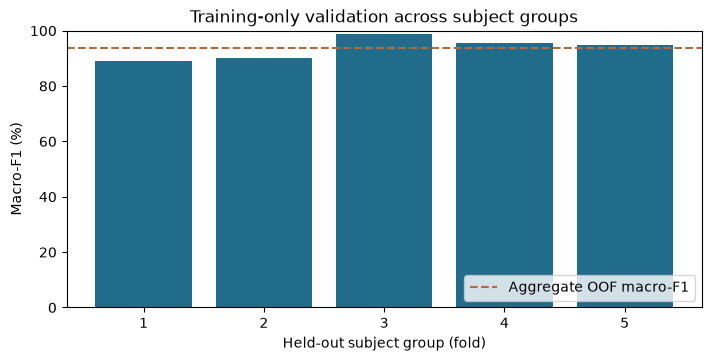

In [6]:
rows = ["| Activity | Precision | Recall | F1 | Windows |", "|---|---:|---:|---:|---:|"]
for label, name in zip(CLASSES, ACTIVITIES):
    score = oof_report[str(label)]
    rows.append(f"| {name} | {score['precision']:.2%} | {score['recall']:.2%} | "
                f"{score['f1-score']:.2%} | {int(score['support'])} |")
display(Markdown("\n".join(rows)))

fig, ax = plt.subplots(figsize=(7, 3.5), layout="constrained")
ax.bar([row["fold"] for row in fold_rows],
       [100 * row["macro_f1"] for row in fold_rows], color="#216b8b")
ax.axhline(100 * validation["oof_macro_f1"], color="#b16b3c", linestyle="--",
           label="Aggregate OOF macro-F1")
ax.set(xlabel="Held-out subject group (fold)", ylabel="Macro-F1 (%)", ylim=(0, 100),
       xticks=range(1, 6), title="Training-only validation across subject groups")
ax.legend(loc="lower right")
fig.savefig(OUT / "oof-folds.png", dpi=160)
plt.show()
plt.close(fig)

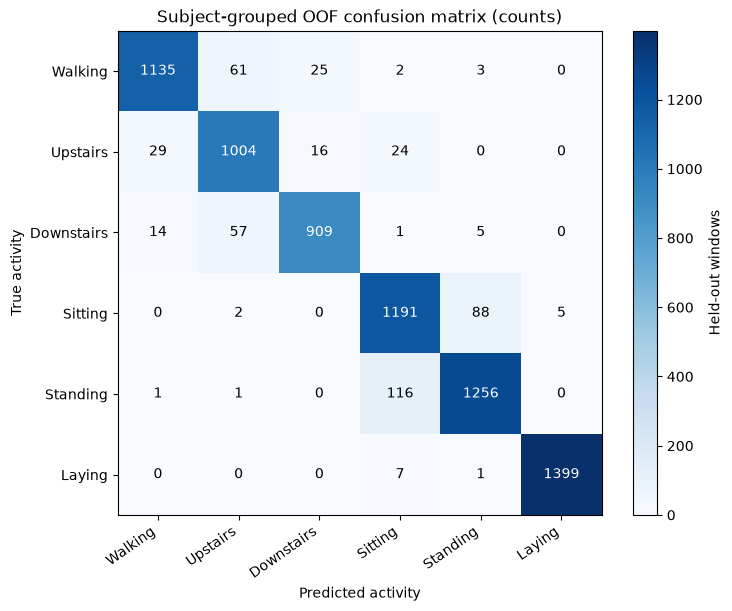

Largest off-diagonal count: Standing -> Sitting 116


In [7]:
fig, ax = plt.subplots(figsize=(7.5, 6), layout="constrained")
image = ax.imshow(oof_matrix, cmap="Blues")
fig.colorbar(image, ax=ax, label="Held-out windows")
ax.set(xticks=range(6), yticks=range(6), xticklabels=ACTIVITIES, yticklabels=ACTIVITIES,
       xlabel="Predicted activity", ylabel="True activity",
       title="Subject-grouped OOF confusion matrix (counts)")
plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
for true_class in range(6):
    for predicted_class in range(6):
        value = oof_matrix[true_class, predicted_class]
        color = "white" if value > oof_matrix.max() / 2 else "black"
        ax.text(predicted_class, true_class, str(value), ha="center", va="center", color=color)
fig.savefig(OUT / "oof-confusion-matrix.png", dpi=160)
plt.show()
plt.close(fig)

# Summarize the largest observed confusion without selecting new parameters
errors_by_pair = oof_matrix.copy()
np.fill_diagonal(errors_by_pair, 0)
true_class, predicted_class = np.unravel_index(np.argmax(errors_by_pair), errors_by_pair.shape)
print("Largest off-diagonal count:", ACTIVITIES[true_class], "->",
      ACTIVITIES[predicted_class], int(errors_by_pair[true_class, predicted_class]))

The bar chart makes the variation between held-out subject groups visible. The confusion matrix provides a complementary view by showing which activities are mistaken for others: rows contain the recorded activities and columns contain the predictions. Entries on the diagonal are correct predictions, while entries elsewhere identify errors. Both figures describe OOF predictions from the training set, so they belong to the same validation procedure as the metrics above.

## 5. Fitting the final model

Having evaluated the fixed training procedure, we now fit a new pipeline on all 21 training subjects using the same hyperparameters. We do not combine or reuse the weights learned by the five fold models. This gives the final candidate the full official training set from which to learn, while leaving the official test set outside the fitting process. The OOF metrics assess the training procedure; they are not a direct measurement of the final candidate on new data.

The fitted pipeline still contains both a scaler and a classifier. To prepare it for the dongle, we combine their calculations into a single set of classifier coefficients. Each weight is divided by the corresponding feature's standard deviation, and the bias, or constant term, is adjusted to account for the feature means. For each activity, the score is the sum of the feature values multiplied by their adjusted weights, plus the adjusted bias. The resulting predictor accepts the published UCI features in their original order without applying our scaler again. These inputs are already processed dataset features, not raw accelerometer or gyroscope readings. The algebraic transformation preserves the decision rule, subject to numerical rounding in the exported implementation.

The next cell checks that this transformation preserves the pipeline's predictions on the training rows. The resulting scores serve to choose an activity; they are not probabilities and should not be interpreted as confidence percentages.


In [8]:
final_pipeline = clone(pipeline).fit(X, y)
scaler, svm = final_pipeline.steps[0][1], final_pipeline.steps[1][1]
weights = svm.coef_ / scaler.scale_
bias = svm.intercept_ - weights @ scaler.mean_
candidate = {
    "name": "svm561",
    "classes": svm.classes_.tolist(),
    "indices": list(range(561)),
    "weights": weights.tolist(),
    "bias": bias.tolist(),
}
candidate_path = OUT / "svm561.json"
candidate_path.write_text(json.dumps(candidate))
validation["candidate_sha256"] = hashlib.sha256(candidate_path.read_bytes()).hexdigest()
(OUT / "validation.json").write_text(json.dumps(validation, indent=2) + "\n")

# Check the algebraic transformation on training inputs without using test data
folded_predictions = np.asarray(candidate["classes"])[(X @ weights.T + bias).argmax(axis=1)]
assert np.array_equal(folded_predictions, final_pipeline.predict(X))
print("Candidate saved:", candidate_path)
print("Fitted scaler rows:", scaler.n_samples_seen_)
print("Folded-coefficient predictions match the fitted pipeline on training rows")

Candidate saved: /Users/martina/ActivityLink-IoT-2026/results/2026-11-04-notebook-review/artifacts/svm561.json
Fitted scaler rows: 7352.0
Folded-coefficient predictions match the fitted pipeline on training rows


## 6. Exporting the models to C

The newly fitted model is a candidate produced by this run. We keep it separate from `models/svm561.json`, the reference already used by the firmware and the recorded hardware experiments. This distinction allows us to reproduce training without silently changing the model behind those experiments.

For each model, the exporter writes arrays of 32-bit floating-point coefficients and a C function that calculates the six activity scores and returns the selected label. We regenerate the reference header and compare it with the firmware header, checking that they match exactly. We also save the candidate's header separately so that its exported implementation can be inspected.

These files remain in the current output directory; running the notebook neither replaces the deployed model nor flashes a board. Later comparisons may show that the candidate and reference make the same predictions on the available windows. Such agreement concerns those inputs and does not establish that their coefficients are identical or that they will agree on every possible measurement.


In [9]:
def export_header(model):
    assert model["classes"] == [1, 2, 3, 4, 5, 6]
    assert model["indices"] == list(range(561))
    lines = ["/* Input: all 561 UCI HAR features in original dataset order */",
             "#include <stddef.h>"]
    for name, array in [
        ("weights", np.asarray(model["weights"], dtype=np.float32).ravel()),
        ("bias", np.asarray(model["bias"], dtype=np.float32)),
    ]:
        lines.append(
            f"static const float har_{name}[{array.size}]={{"
            + ",".join(f"{float(value):.9e}f" for value in array)
            + "};"
        )
    lines.append(
        "int har_predict(const float x[561]) {\n"
        "  int best = 0;\n"
        "  float top = 0;\n"
        "  for (int c = 0; c < 6; c++) {\n"
        "    float s = har_bias[c];\n"
        "    for (int j = 0; j < 561; j++)\n"
        "      s += har_weights[c * 561 + j] * x[j];\n"
        "    if (c == 0 || s > top) {\n"
        "      top = s;\n"
        "      best = c;\n"
        "    }\n"
        "  }\n"
        "  return best + 1;\n"
        "}"
    )
    return "\n".join(lines)

frozen = json.loads((ROOT / "models/svm561.json").read_text())
reference_header = export_header(frozen)
assert reference_header == (ROOT / "firmware/node/model.h").read_text()
(OUT / "har_linear_predictor.h").write_text(reference_header)
(OUT / "candidate_predictor.h").write_text(export_header(candidate))
print("Frozen reference header SHA-256:", hashlib.sha256(reference_header.encode()).hexdigest())
print("Candidate header exported separately; deployed files are unchanged")

Frozen reference header SHA-256: 998dd3f949ff30a3fbb0564ec623e837623cc87fc46c84cfa5878c3b72da7f99
Candidate header exported separately; deployed files are unchanged


## 7. Checking the C implementation

Exporting a trained model introduces a second implementation of its prediction calculation. We therefore compile the reference predictor on the host computer and compare its outputs with predictions calculated in Python from the same reference JSON coefficients. All 2,947 official test feature vectors provide inputs for this comparison, but their activity labels are not needed: the question here is whether the two implementations return the same answers.

No model is fitted or selected during this check. Agreement supports the consistency of the C and Python implementations on these inputs, rather than measuring whether their answers describe the activities correctly. The compiled code runs on the host computer during this verification, so this is also distinct from execution on the dongle's ARM processor. We consider the recorded activity labels separately in the following section.


In [10]:
if shutil.which("gcc") is None:
    raise RuntimeError("Install a host C compiler before running the equivalence check")
command = [sys.executable, "scripts/verify_model.py", "--dataset", str(DATASET),
           "--output", str(OUT / "equivalence.json")]
subprocess.run(command, check=True, capture_output=True, text=True)
equivalence = json.loads((OUT / "equivalence.json").read_text())
print("Scope:", equivalence["scope"])
print("Compared input windows:", equivalence["samples"])
print("C/Python prediction mismatches:", equivalence["mismatches"])
print("Compiler:", equivalence["compiler"])

Scope: host GCC; shipped JSON vs shipped C; no ARM execution
Compared input windows: 2947
C/Python prediction mismatches: 0
Compiler: Apple clang version 14.0.0 (clang-1400.0.29.202)


## 8. Historical test results

We now compare the saved candidate's predictions with the activity labels in the official test split. Before calculating the metrics, the evaluation script checks that the nine test subjects are distinct from the training subjects. This step evaluates the already fitted model without changing its parameters.

Although the subjects are separate, this test set was consulted earlier in the project. Its scores therefore provide a historical benchmark rather than a new blind evaluation, and they do not determine whether the current candidate is accepted. The accompanying comparison with the deployed reference helps relate this run to the existing firmware. As discussed above, different coefficients can still produce the same predictions on these windows, so we interpret prediction agreement within that scope.


In [11]:
command = [sys.executable, "ml/evaluate_historical.py", "--dataset", str(DATASET),
           "--candidate", str(candidate_path), "--output", str(OUT / "historical-test.json")]
subprocess.run(command, check=True, capture_output=True, text=True)
historical = json.loads((OUT / "historical-test.json").read_text())
assert historical["subject_overlap"] == 0
assert not historical["used_for_selection"]
assert not historical["firmware_replaced"]
rows = ["| Evaluation | Windows | Accuracy | Macro-F1 |",
        "|---|---:|---:|---:|",
        f"| Training-only subject-grouped OOF | {len(y)} | {validation['oof_accuracy']:.2%} | {validation['oof_macro_f1']:.2%} |",
        f"| Previously consulted official test | {historical['test_rows']} | {historical['accuracy']:.2%} | {historical['macro_f1']:.2%} |"]
display(Markdown("\n".join(rows)))
print("Historical test errors:", historical["errors"])
print("Candidate/reference prediction differences:", historical["prediction_mismatches_vs_shipped"])
print("Maximum candidate/reference coefficient difference:", historical["max_weight_difference"])

| Evaluation | Windows | Accuracy | Macro-F1 |
|---|---:|---:|---:|
| Training-only subject-grouped OOF | 7352 | 93.77% | 93.66% |
| Previously consulted official test | 2947 | 96.20% | 96.29% |

Historical test errors: 112
Candidate/reference prediction differences: 0
Maximum candidate/reference coefficient difference: 0.02430758485230644


## 9. Output files and interpretation

The output directory preserves the steps needed to inspect and reproduce this run. The configuration and validation results are recorded in `protocol.json` and `validation.json`, including the training-file hashes and fold metrics. The individual held-out predictions are available in `oof_predictions.csv`, while `oof-folds.png` and `oof-confusion-matrix.png` contain the two validation figures displayed above.

The fitted candidate is saved as `svm561.json` alongside its C export, `candidate_predictor.h`. The separate `har_linear_predictor.h` reproduces the reference header used in the firmware comparison. We keep the implementation comparison in `equivalence.json` and the historical benchmark in `historical-test.json`, since they address different questions. Finally, `execution-summary.json` records the execution environment and the checks that the deployed model files remain unchanged.

Taken together, these results describe both predictive performance and implementation consistency. We use OOF macro-F1 as the main performance measure and read the individual fold results to understand variation between people. The historical test benchmark adds context, while the C/Python comparison checks that the exported calculation agrees with its reference on the evaluated inputs.

The scope remains activity recognition from the prepared UCI features. These results do not establish accuracy with new sensors, a different feature-extraction procedure or live patient monitoring. Similarly, replaying the 24 stored vectors demonstrates execution on the dongle without providing an additional accuracy estimate. A new independent evaluation would require previously unseen data and a protocol fixed before examining its results.

For reproduction outside the notebook, `ml/retrain.py` implements the same training configuration. The historical evaluator and C verifier are shared with this notebook, connecting the interactive explanation to the command-line workflow. The final cell records the environment and confirms that the deployed model files have been preserved.


In [12]:
for path in REFERENCE_PATHS:
    assert hashlib.sha256(path.read_bytes()).hexdigest() == reference_hashes[str(path.relative_to(ROOT))]
summary = {
    "completed_at": datetime.now(timezone.utc).isoformat(),
    "runtime": "Google Colab" if IN_COLAB else "local Jupyter kernel",
    "hosted_colab_verified": IN_COLAB,
    "python": sys.version.split()[0],
    "numpy": np.__version__,
    "sklearn": sklearn.__version__,
    "matplotlib": matplotlib.__version__,
    "official_test_used_for_training_or_selection": False,
    "historical_test_reported_separately": True,
    "deployed_model_files_unchanged": True,
    "reference_sha256": reference_hashes,
    "oof_macro_f1": validation["oof_macro_f1"],
    "oof_accuracy": validation["oof_accuracy"],
    "host_c_prediction_mismatches": equivalence["mismatches"],
    "output_directory": str(OUT),
}
(OUT / "execution-summary.json").write_text(json.dumps(summary, indent=2) + "\n")
print("Completed: outputs saved and deployed model files unchanged")
print("Hosted Google Colab execution verified in this run:", IN_COLAB)

Completed: outputs saved and deployed model files unchanged
Hosted Google Colab execution verified in this run: False


## References

The dataset and software documentation below provide the sources for the data, learning components and execution options used in this notebook.

- Reyes-Ortiz et al., *Human Activity Recognition Using Smartphones*, UCI Machine Learning Repository: https://doi.org/10.24432/C54S4K
- Dataset licence: https://creativecommons.org/licenses/by/4.0/
- scikit-learn, StandardScaler: https://scikit-learn.org/1.8/modules/generated/sklearn.preprocessing.StandardScaler.html
- scikit-learn, LinearSVC: https://scikit-learn.org/1.8/modules/generated/sklearn.svm.LinearSVC.html
- scikit-learn, GroupKFold: https://scikit-learn.org/1.8/modules/generated/sklearn.model_selection.GroupKFold.html
- scikit-learn, avoiding data leakage: https://scikit-learn.org/1.8/common_pitfalls.html#data-leakage
- Google Colab, loading local files: https://colab.research.google.com/notebooks/io.ipynb

Further methodological details are provided in `docs/ML_VALIDATION.md` and the English project report. The saved outputs in this notebook come from a local Jupyter execution.
